In [1]:
from pathlib import Path
from google.colab import drive
import os, sys, json, zipfile, subprocess, shutil
from datetime import datetime, timezone
drive.mount('/content/drive')
WORK = Path('/content/unifashion_week8')
PERSIST = Path('/content/drive/MyDrive/Thesis/UniFashion/week8')
INPUT_DIR = PERSIST / 'inputs'
TRAIN_RUN = PERSIST / 'runs/full_train_fp32_b2_seed42'
assert (TRAIN_RUN / 'last.pt').is_file(), f'Missing checkpoint: {TRAIN_RUN}'
WORK.mkdir(parents=True, exist_ok=True)
for name in ('unifashion_week8_code.zip', 'unifashion_week8_data.zip', 'unifashion_recall_eval.zip'):
    if name == 'unifashion_week8_data.zip' and (WORK / 'data/data_audit.json').exists() and (WORK / 'images').exists():
        continue
    with zipfile.ZipFile(INPUT_DIR / name) as archive:
        for member in archive.namelist():
            if not (WORK / member).resolve().is_relative_to(WORK.resolve()):
                raise ValueError(member)
        archive.extractall(WORK)
os.chdir(WORK)
os.environ['HF_HOME'] = str(WORK / '.cache/huggingface')
cache = PERSIST / 'pretrained_assets'
cache.mkdir(parents=True, exist_ok=True)
(WORK / 'checkpoints').mkdir(exist_ok=True)
link = WORK / 'checkpoints/unifashion'
if not link.exists():
    link.symlink_to(cache, target_is_directory=True)
def run_live(command):
    with subprocess.Popen(command, cwd=WORK, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                          text=True, bufsize=1) as process:
        for line in process.stdout:
            print(line, end='', flush=True)
        if process.wait():
            raise RuntimeError(f'Command exited {process.returncode}; see output above')


Mounted at /content/drive


In [2]:
if not ((3, 10) <= sys.version_info[:2] <= (3, 12)):
    raise RuntimeError('Use a Python 3.10–3.12 runtime for the pinned environment')
run_live([sys.executable, '-m', 'pip', 'install', '-r', 'requirements-unifashion.txt'])
run_live([sys.executable, '-B', 'scripts/check_unifashion_environment.py'])
run_live([sys.executable, '-c', 'import torch; assert torch.cuda.is_available(); print(torch.cuda.get_device_name())'])
run_live([sys.executable, '-B', '-u', 'scripts/download_unifashion.py', '--with-vision'])
run_live([sys.executable, '-B', '-m', 'pytest', 'tests/test_fashioniq_evaluation.py', '-q'])


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.8/126.8 kB 8.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 7.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 3.5 MB/s eta 0:00:00
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 266.3/266.3 kB 17.9 MB/s eta 0:00:00
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Installing backend dependencies: started
  Installing backend dependencies: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 11.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 

In [3]:
EVAL_ROOT = PERSIST / 'evaluations' / ('fp32_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ'))
EVAL_ROOT.mkdir(parents=True, exist_ok=False)
SNAPSHOT = EVAL_ROOT / 'fp32_snapshot.pt'
source = TRAIN_RUN / 'last.pt'
before = (source.stat().st_size, source.stat().st_mtime_ns)
print('Copying checkpoint; wait for completion...', flush=True)
shutil.copyfile(source, SNAPSHOT)
after = (source.stat().st_size, source.stat().st_mtime_ns)
if before != after or SNAPSHOT.stat().st_size != before[0]:
    raise RuntimeError('Checkpoint changed during copying; stop training and make a new snapshot')
for name in ('config.json', 'status.json', 'checkpoint_load.json', 'epoch_metrics.csv'):
    path = TRAIN_RUN / name
    if path.exists():
        shutil.copyfile(path, EVAL_ROOT / ('training_' + name))
print('Snapshot:', SNAPSHOT)
RESULTS = EVAL_ROOT / 'results'


Copying checkpoint; wait for completion...
Snapshot: /content/drive/MyDrive/Thesis/UniFashion/week8/evaluations/fp32_20261013T082550Z/fp32_snapshot.pt


In [4]:
run_live([sys.executable, '-B', '-u', 'scripts/evaluate_unifashion_fashioniq.py',
          '--checkpoint', str(SNAPSHOT), '--eval-data', str(WORK / 'evaluation_inputs/evaluation_data'),
          '--data-dir', str(WORK / 'data'), '--images-dir', str(WORK / 'images'),
          '--output', str(RESULTS), '--batch-size', '4'])


Reading and hashing the checkpoint snapshot...
Verifying 15415 validation images...
Verifying the frozen EVA-G checkpoint...
Snapshot progress: {"optimizer_steps": 29500, "completed_epochs": 3, "next_epoch_one_based": 4, "completed_batches_in_current_epoch": 2500}
/usr/local/lib/python3.12/dist-packages/transformers/utils/generic.py:441: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
/usr/local/lib/python3.12/dist-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
dress: gallery 100/3817
dress: gallery 200/3817
dress: gallery 300/3817
dress: gallery 400/3817
dress: gallery 500/3817
dress: gallery 600/3817
dress: gallery 700/3817
dress: gallery 800/3817
dress: gallery 900/3817
dress: gallery 10

                        method category  queries  gallery_size  Recall@10  Recall@50  delta_R@10_pp_vs_additive  delta_R@50_pp_vs_additive
          fashionclip_additive    MACRO     6016           NaN  23.622107  41.536904                   0.000000                   0.000000
        fashionclip_image_only    MACRO     6016           NaN   7.606737  16.922231                 -16.015371                 -24.614673
         fashionclip_text_only    MACRO     6016           NaN  27.780309  47.100548                   4.158202                   5.563645
unifashion_image_caption_score    MACRO     6016           NaN  57.075531  75.430589                  33.453423                  33.893685
        unifashion_image_score    MACRO     6016           NaN  36.211229  60.408497                  12.589122                  18.871593


# Đánh giá Recall@10/@50 trên FashionIQ validation

Giao thức: toàn bộ 6.016 query; gallery dress 3.817, shirt 6.346, toptee 5.373; loại ảnh reference khỏi ranking. Recall trình bày theo phần trăm. Macro là trung bình đều ba loại; micro là trung bình theo query. Khi score bằng nhau, dùng thứ tự gallery chính thức để phá hòa.

Raw query text dùng đúng cột text trong metadata FashionCLIP của Tuần 6 cho mọi mô hình. Mỗi encoder áp dụng normalization/tokenization riêng. UniFashion dùng clean_caption giống pipeline train; format raw text này khác cách nối bằng 'and' của CSV train và script validation upstream, được chọn để thống nhất đầu vào với cached baseline.

## Kết quả đo được

| Method | Category | Queries | R@10 (%) | R@50 (%) | Δ R@10 (pp) | Δ R@50 (pp) |
|---|---|---:|---:|---:|---:|---:|
| fashionclip_additive | dress | 2017 | 21.91 | 41.79 | +0.00 | +0.00 |
| fashionclip_additive | shirt | 2038 | 22.13 | 37.63 | +0.00 | +0.00 |
| fashionclip_additive | toptee | 1961 | 26.82 | 45.18 | +0.00 | +0.00 |
| fashionclip_additive | MACRO | 6016 | 23.62 | 41.54 | +0.00 | +0.00 |
| fashionclip_additive | MICRO | 6016 | 23.59 | 41.49 | +0.00 | +0.00 |
| fashionclip_image_only | dress | 2017 | 6.40 | 15.22 | -15.52 | -26.57 |
| fashionclip_image_only | shirt | 2038 | 8.98 | 18.11 | -13.15 | -19.53 |
| fashionclip_image_only | toptee | 1961 | 7.45 | 17.44 | -19.38 | -27.74 |
| fashionclip_image_only | MACRO | 6016 | 7.61 | 16.92 | -16.02 | -24.61 |
| fashionclip_image_only | MICRO | 6016 | 7.61 | 16.92 | -15.97 | -24.57 |
| fashionclip_text_only | dress | 2017 | 24.39 | 44.67 | +2.48 | +2.88 |
| fashionclip_text_only | shirt | 2038 | 26.01 | 42.93 | +3.88 | +5.30 |
| fashionclip_text_only | toptee | 1961 | 32.94 | 53.70 | +6.12 | +8.52 |
| fashionclip_text_only | MACRO | 6016 | 27.78 | 47.10 | +4.16 | +5.56 |
| fashionclip_text_only | MICRO | 6016 | 27.73 | 47.02 | +4.14 | +5.54 |
| unifashion_image_caption_score | dress | 2017 | 54.29 | 73.03 | +32.37 | +31.23 |
| unifashion_image_caption_score | shirt | 2038 | 55.64 | 73.41 | +33.51 | +35.77 |
| unifashion_image_caption_score | toptee | 1961 | 61.30 | 79.86 | +34.47 | +34.68 |
| unifashion_image_caption_score | MACRO | 6016 | 57.08 | 75.43 | +33.45 | +33.89 |
| unifashion_image_caption_score | MICRO | 6016 | 57.03 | 75.38 | +33.44 | +33.89 |
| unifashion_image_score | dress | 2017 | 28.16 | 54.14 | +6.25 | +12.35 |
| unifashion_image_score | shirt | 2038 | 38.86 | 60.84 | +16.73 | +23.21 |
| unifashion_image_score | toptee | 1961 | 41.61 | 66.24 | +14.79 | +21.06 |
| unifashion_image_score | MACRO | 6016 | 36.21 | 60.41 | +12.59 | +18.87 |
| unifashion_image_score | MICRO | 6016 | 36.17 | 60.36 | +12.58 | +18.87 |

![Kết quả thực đo](recall_comparison.png)

Δ tính theo điểm phần trăm so với FashionCLIP additive cùng category, không phải phần trăm tăng tương đối.

## Nguồn baseline và giới hạn

Baseline additive theo notebook `38_18_FashionIQ_RecallK.ipynb`: normalize(image + text), cosine với gallery. Notebook này đã dùng gallery chính thức và loại reference. Script cũ `evaluate_baseline_fashioniq.py` dùng gallery target-only, nên không lấy số từ script đó để trộn vào bảng. Các kết quả ở đây được tính lại từ embedding hiện có, có SHA-256 nguồn và CSV rank từng query.

Image-only và text-only là ablation bổ sung. Concat ảnh + SBERT với target zero-padding trong script cũ không làm text thay đổi thứ hạng cosine: tương đương image-only về ranking, không coi là fusion học được.

Cached FashionCLIP embeddings dùng preprocessing theo mô hình của lần trích xuất cũ; chưa đối chiếu pixel ảnh gốc từ máy thành viên với bộ ảnh resized hiện tại. Đây là so sánh các hệ thống trên cùng query/gallery, chưa phải kiểm soát hoàn toàn ảnh nguồn hoặc tái lập số liệu paper.

## Checkpoint UniFashion và diễn giải

- unifashion_image_caption_score: checkpoint `fp32_snapshot.pt`, SHA-256 `f4e9ee1f8c2dda190e7d4854e963426ef466b60455154a01e3b12cd0647872fb`; 29500 update, 3 epoch hoàn tất và 2500 batch trong epoch kế tiếp. Macro R@10=57.08%, R@50=75.43%.
- unifashion_image_score: checkpoint `fp32_snapshot.pt`, SHA-256 `f4e9ee1f8c2dda190e7d4854e963426ef466b60455154a01e3b12cd0647872fb`; 29500 update, 3 epoch hoàn tất và 2500 batch trong epoch kế tiếp. Macro R@10=36.21%, R@50=60.41%.

`unifashion_image_score` vẫn dùng query ảnh + mô tả; chỉ bỏ phần score caption gallery. `unifashion_image_caption_score` cộng score caption ảnh gallery được phát hành cùng UniFashion, áp dụng cho tất cả ứng viên; không đưa caption của ground-truth target vào query và không ITM rerank.

Đây là đánh giá checkpoint ở tiến độ ghi trên snapshot; không gọi là hoàn tất 10 epoch nếu chưa đủ. Nếu chọn checkpoint dựa trên val, cần công bố quy trình lựa chọn; không diễn giải val như test độc lập. Chưa có so sánh UniFashion trước/sau fine-tune nên chênh lệch với FashionCLIP chưa cô lập tác dụng fine-tune.


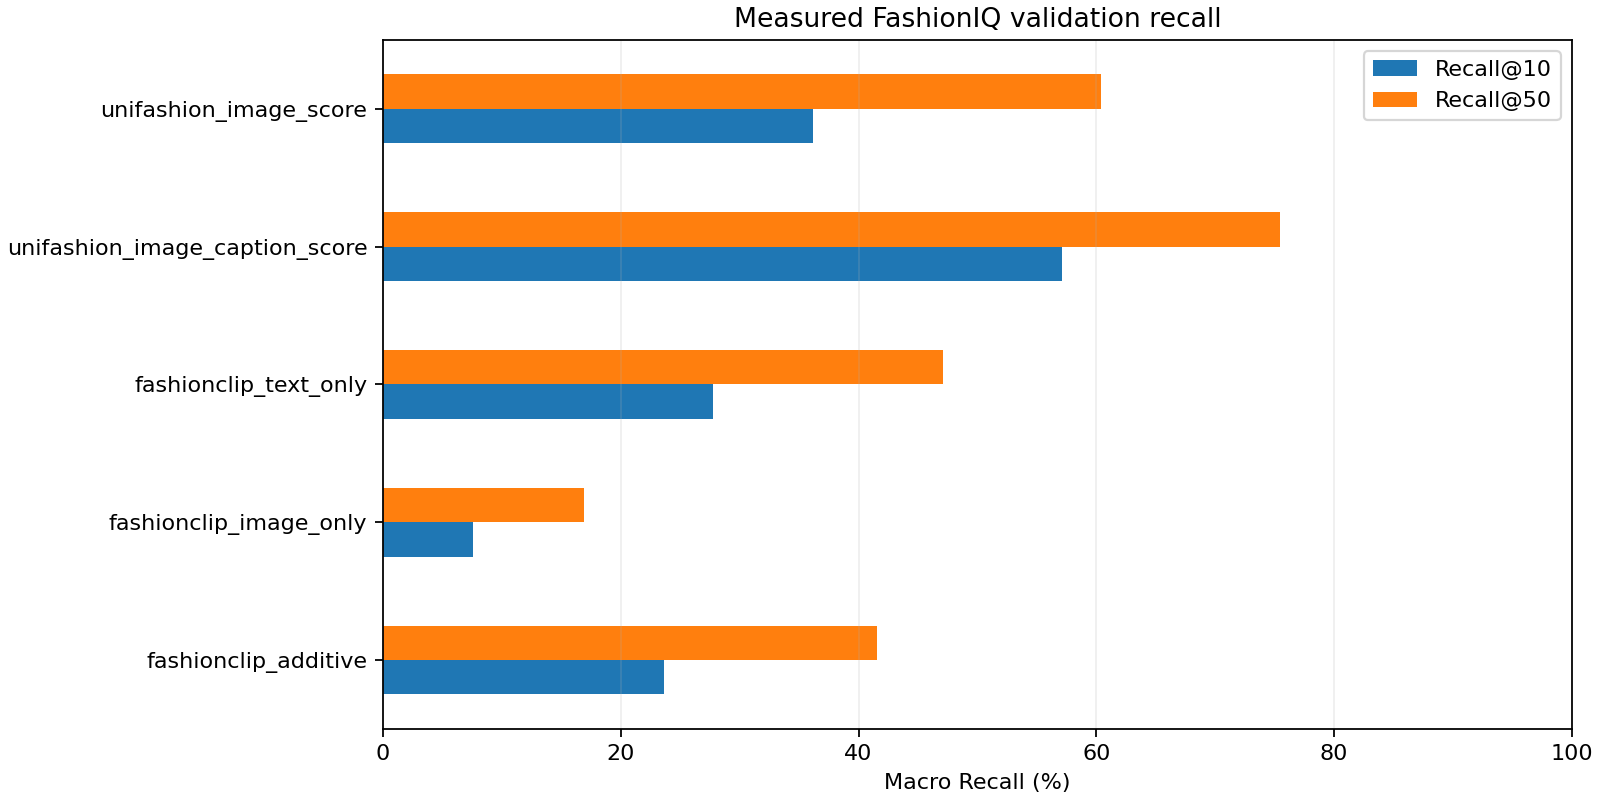

Exact checkpoint progress: {
  "checkpoint_sha256": "f4e9ee1f8c2dda190e7d4854e963426ef466b60455154a01e3b12cd0647872fb",
  "snapshot": "fp32_snapshot.pt",
  "optimizer_steps": 29500,
  "completed_epochs": 3,
  "next_epoch_one_based": 4,
  "completed_batches_in_current_epoch": 2500,
  "planned_epochs": 10,
  "training_config": {
    "seed": 42,
    "epochs": 10,
    "batch_size": 2,
    "learning_rate": 2e-05,
    "weight_decay": 0.05,
    "betas": [
      0.9,
      0.98
    ],
    "eps": 1e-07,
    "scheduler": "one_cycle",
    "warmup_epochs": 1.5,
    "div_factor": 100.0,
    "final_div_factor": 10000.0,
    "max_grad_norm": 1.0,
    "image_size": 224,
    "target_ratio": 1.25,
    "max_txt_len": 64,
    "num_workers": 0,
    "precision": "fp32",
    "grad_scaler_init_scale": 256.0,
    "max_amp_retries": 10,
    "freeze_vit": true,
    "checkpoint_every_steps": 500,
    "monitor_per_category": 32,
    "description": "Full FashionIQ train, upstream 10-epoch OneCycle/AdamW settings; F

In [5]:
run_live([sys.executable, '-B', 'scripts/report_fashioniq_evaluation.py',
          '--baselines', str(WORK / 'evaluation_inputs/baselines'),
          '--evaluation', str(RESULTS), '--output', str(EVAL_ROOT / 'report')])
from IPython.display import display, Markdown, Image
display(Markdown((EVAL_ROOT / 'report/evaluation_report.md').read_text()))
display(Image(filename=str(EVAL_ROOT / 'report/recall_comparison.png')))
print('Exact checkpoint progress:', (RESULTS / 'provenance.json').read_text())


In [6]:
evidence_zip = EVAL_ROOT / 'evaluation_evidence.zip'
with zipfile.ZipFile(evidence_zip, 'w', zipfile.ZIP_DEFLATED) as archive:
    for folder in (RESULTS, EVAL_ROOT / 'report'):
        for path in folder.iterdir():
            if path.is_file():
                archive.write(path, path.relative_to(EVAL_ROOT))
    for path in EVAL_ROOT.glob('training_*'):
        archive.write(path, path.name)
print('Send this small ZIP to review results:', evidence_zip)
print('Keep the checkpoint snapshot on Drive:', SNAPSHOT)


Send this small ZIP to review results: /content/drive/MyDrive/Thesis/UniFashion/week8/evaluations/fp32_20261013T082550Z/evaluation_evidence.zip
Keep the checkpoint snapshot on Drive: /content/drive/MyDrive/Thesis/UniFashion/week8/evaluations/fp32_20261013T082550Z/fp32_snapshot.pt
